# 00 · Data and baseline

**Goal:** get the numbers to beat. `precursor2cof-capacitance` saved no scores, so this notebook reruns
its best models with its exact protocol, then evaluates them again under the protocol used in all
later notebooks.

- **Old protocol:** one stratified 10-fold split (seed 42). In each fold, Optuna (QMC, 100 trials)
  minimises RMSE on a single 70/30 split of the training part. Metrics are averaged over folds.
- **New protocol:** 5 × 10-fold stratified CV (seeds 0–4). Metrics are computed on the 114 pooled
  out-of-fold predictions of each repeat, then mean ± std over the 5 repeats.

Models (best feature sets found by the old greedy forward selection):
- Bayesian ridge (BRR): descriptors + ECFP + EState + functional groups
- Random forest (RF): EState + functional groups
- XGBoost: EState + functional groups (no best set was recorded for it, so it uses RF's)

In [1]:
import os
import sys
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"  # also silences joblib worker processes
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cofreg import plots
from cofreg.cv import cross_val_oof, old_protocol_folds, per_fold_scores, repeated_folds, run_many, summarize
from cofreg.data import RESULTS_DIR, load_data, load_features
from cofreg.models import MedianBaseline, OldProtocolTuned

plots.style()
EXPERIMENT = "00_baseline"
data = load_data()
y = data.capacity_max.to_numpy()

## The data

114 substrates with a capacity target from 2 to 768. The distribution is wide and skewed toward
small values. The 8 smallest values (2–16) are all pre-joined imine substrates (amine + aldehyde
already linked by `N=C`).

{'count': 114.0, 'mean': 267.4, 'std': 196.6, 'min': 2.0, '25%': 89.8, '50%': 234.0, '75%': 391.8, 'max': 768.0}


,smiles,capacity_max
50,Nc1ccc(-c2nc(-c3ccc(N)cc3)nc(-c3ccc(/N=C/c4ccc...,2.0
94,Nc1c(N)c(O)c(NCc2cc(O)c(C=O)cc2O)c(N)c1O,3.0
48,Nc1ccc(N(c2ccc(N)cc2)c2ccc(/N=C/c3ccc(-c4nc(-c...,5.0
28,Nc1ccc(-c2ccc3[nH]c(-c4cc(C(=O)O)cc(N5C(=O)c6c...,6.0
51,Nc1ccc(-n2c3ccc(N)cc3c3cc(/N=C/c4ccc(N(c5ccc(C...,14.0
47,Nc1ccc(N(c2ccc(N)cc2)c2ccc(/N=C/c3ccc(-c4cc(-c...,14.0
54,Nc1ccc(-n2c3ccc(N)cc3c3cc(/N=C/c4ccc(-c5cc(-c6...,15.0
52,Nc1ccc(-c2nc(-c3ccc(N)cc3)nc(-c3ccc(/N=C/c4ccc...,16.0


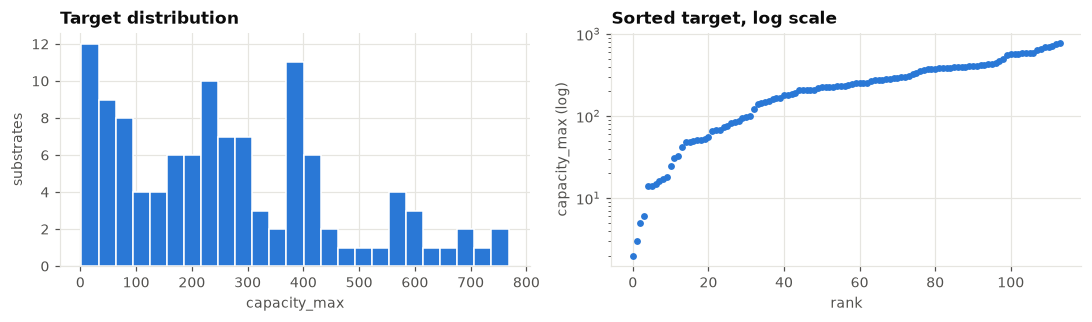

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(y, bins=25, color=plots.BLUE, edgecolor="white")
axes[0].set(xlabel="capacity_max", ylabel="substrates")
axes[0].set_title("Target distribution", loc="left")
axes[1].scatter(np.arange(len(y)), np.sort(y), s=12, color=plots.BLUE)
axes[1].set(yscale="log", xlabel="rank", ylabel="capacity_max (log)")
axes[1].set_title("Sorted target, log scale", loc="left")
fig.tight_layout()
print(pd.Series(y).describe().round(1).to_dict())
data.sort_values("capacity_max").head(8)

## Old protocol, old split

These numbers are directly comparable with what the old pipeline would print.

In [3]:
X_brr = load_features("descriptor", "ecfp", "estate", "functional_groups")
X_rf = load_features("estate", "functional_groups")
MODELS = [
    ("median", MedianBaseline(), X_rf, "-"),
    ("old_brr", OldProtocolTuned("bayes"), X_brr, "descriptor+ecfp+estate+fg"),
    ("old_rf", OldProtocolTuned("random_forest"), X_rf, "estate+fg"),
    ("old_xgb", OldProtocolTuned("xgboost"), X_rf, "estate+fg"),
]

old_folds = old_protocol_folds(y)
rows = []
for name, model, X, feats in MODELS:
    oof = cross_val_oof(model, X, y, [old_folds])
    rows.append({"model": name, "features": feats} | per_fold_scores(y, oof[0], old_folds).mean().to_dict())
old_table = pd.DataFrame(rows)
old_table.round(3)

,model,features,mape,pa,rmse,smape,mae,r2,male,mape_ge20
0,median,-,4.102,0.500,198.299,0.692,157.945,-0.038,0.876,0.962
1,old_brr,descriptor+ecfp+estate+fg,3.613,0.701,173.409,0.614,135.124,0.203,0.769,0.826
2,old_rf,estate+fg,2.682,0.690,178.305,0.600,137.957,0.139,0.720,0.883
3,old_xgb,estate+fg,3.235,0.661,188.168,0.648,147.878,0.058,0.789,0.957


## New protocol (used from here on)

Same models, 5 repeats of 10-fold CV, pooled out-of-fold metrics. MALE is the mean absolute log
error (exp(MALE) is the typical multiplicative error); `mape_ge20` is MAPE on targets ≥ 20 only.

In [4]:
repeats = repeated_folds(y)
summary = run_many(MODELS, y, repeats, EXPERIMENT)
summary.to_csv(os.path.join(RESULTS_DIR, EXPERIMENT, "summary.csv"), index=False)
summary[["model", "features", "mape_mean", "mape_std", "pa_mean", "pa_std", "rmse_mean", "rmse_std", "male_mean", "mape_ge20_mean", "r2_mean"]].round(3)

median                                        MAPE 4.065±0.013  PA 0.470±0.003  RMSE 198.8±0.1  MALE 0.873  (0.0s)


old_brr                                       MAPE 3.655±0.080  PA 0.666±0.009  RMSE 177.8±2.6  MALE 0.786  (4.2s)


old_rf                                        MAPE 2.687±0.255  PA 0.652±0.011  RMSE 182.4±3.7  MALE 0.754  (23.0s)


old_xgb                                       MAPE 3.227±0.127  PA 0.648±0.015  RMSE 182.7±3.0  MALE 0.779  (5.2s)


,model,features,mape_mean,mape_std,pa_mean,pa_std,rmse_mean,rmse_std,male_mean,mape_ge20_mean,r2_mean
0,median,-,4.065,0.013,0.470,0.003,198.763,0.059,0.873,0.972,-0.032
1,old_brr,descriptor+ecfp+estate+fg,3.655,0.080,0.666,0.009,177.788,2.592,0.786,0.850,0.174
2,old_rf,estate+fg,2.687,0.255,0.652,0.011,182.374,3.722,0.754,0.890,0.131
3,old_xgb,estate+fg,3.227,0.127,0.648,0.015,182.726,2.998,0.779,0.914,0.128


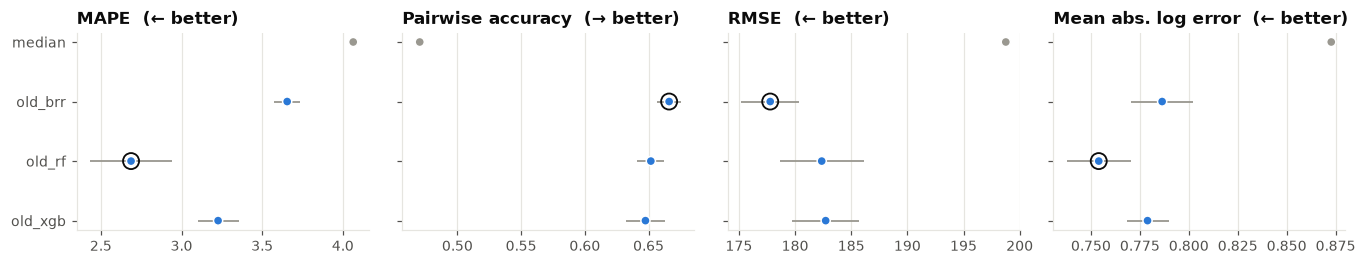

In [5]:
fig = plots.metric_dots(summary, highlight={"median": plots.GRAY})

Per-fold metrics on 11 test points are noisy, and pooled pairwise accuracy is a bit lower than the
per-fold one (it also compares pairs across folds). The models explain little of the variance
(R² ≈ 0.1–0.2).

## Why MAPE is a problem here

MAPE divides by the true value, so the substrates with capacity 2–16 dominate it. The plot below
shows MAPE of a **constant** prediction: the best constant is about 6, and it beats every model.
A model can lower MAPE simply by predicting low values. We keep reporting MAPE as the task asks,
but compare models mainly on pairwise accuracy, RMSE and MALE.

Old RF: the 10 substrates with y < 20 make up 71% of its MAPE


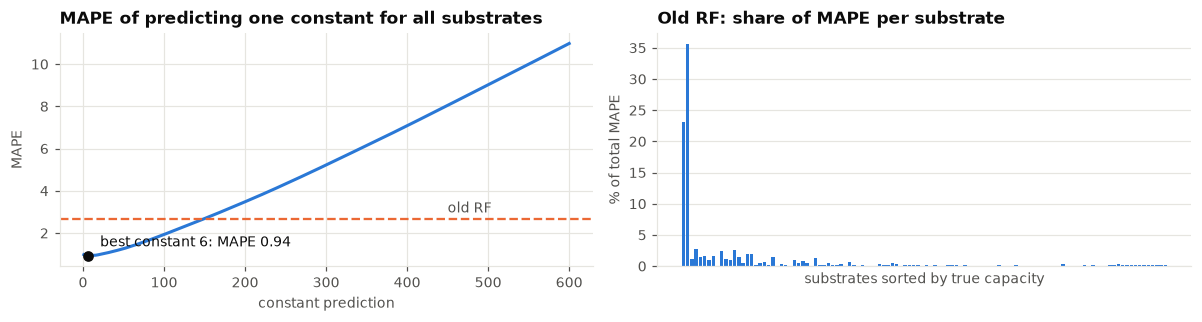

In [6]:
consts = np.linspace(1, 600, 1200)
mape_const = [np.mean(np.abs(c - y) / y) for c in consts]
best = int(np.argmin(mape_const))
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(consts, mape_const, color=plots.BLUE, linewidth=2)
axes[0].axhline(summary.set_index("model").loc["old_rf", "mape_mean"], color=plots.ORANGE, linewidth=1.5, linestyle="--")
axes[0].annotate("old RF", (450, summary.set_index("model").loc["old_rf", "mape_mean"]), textcoords="offset points", xytext=(0, 4), color=plots.INK_2)
axes[0].scatter([consts[best]], [mape_const[best]], color=plots.INK, zorder=3)
axes[0].annotate(f"best constant {consts[best]:.0f}: MAPE {mape_const[best]:.2f}", (consts[best], mape_const[best]), textcoords="offset points", xytext=(8, 6), color=plots.INK)
axes[0].set(xlabel="constant prediction", ylabel="MAPE")
axes[0].set_title("MAPE of predicting one constant for all substrates", loc="left")
_, oof_rf = __import__("cofreg.cv", fromlist=["load_oof"]).load_oof(EXPERIMENT, "old_rf")
plots.ape_contributions(y, oof_rf[0], ax=axes[1], label="Old RF: share of MAPE per substrate")
fig.tight_layout()
share = (np.abs(oof_rf[0] - y) / y)[y < 20].sum() / (np.abs(oof_rf[0] - y) / y).sum()
print(f"Old RF: the {np.sum(y < 20)} substrates with y < 20 make up {share:.0%} of its MAPE")

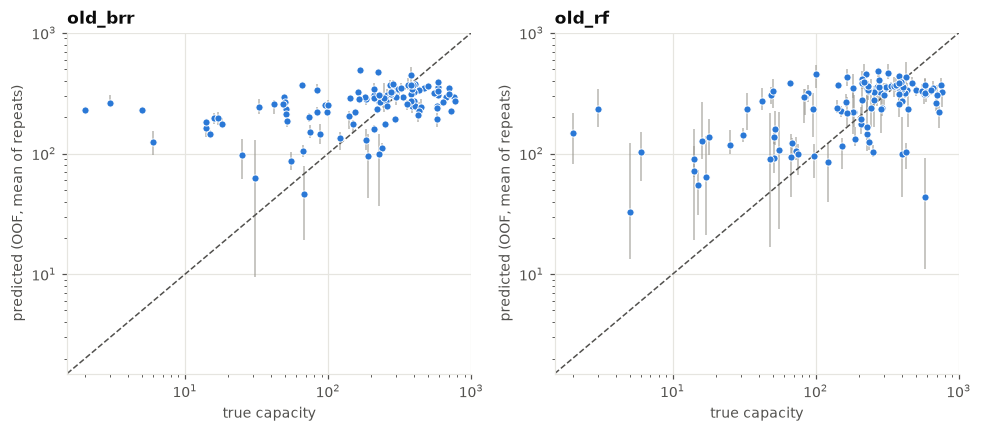

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, name in zip(axes, ["old_brr", "old_rf"]):
    _, oof = __import__("cofreg.cv", fromlist=["load_oof"]).load_oof(EXPERIMENT, name)
    plots.pred_vs_true(y, oof, name, ax=ax)
fig.tight_layout()

## Takeaways

- Baseline to beat (new protocol): **old BRR**: MAPE ≈ 3.66, PA ≈ 0.666, RMSE ≈ 178; **old RF**: MAPE ≈ 2.69, PA ≈ 0.652, RMSE ≈ 182.
- Both models pull predictions toward the middle: small capacities are over-predicted by up to 100×,
  which is where almost all of the MAPE comes from.
- The old Optuna tuning gives the same BRR as untuned defaults (that grid barely changes the model).